# XGBoost / LightGBM: gradient-boosted trees + TF-IDF

**Goal:** same as the logistic regression baseline. Predict whether a certificate program meets the Workforce Pell value-added earnings standard, using numeric program/school data plus the text describing its field and related jobs.

**Target:** `vae_positive_local` (1 = locally adjusted 1-year earnings above $23,475, 0 = at or below)

**Score to beat:** LR text + numeric: **F1 0.925 / ROC-AUC 0.947** (team RF/XGBoost baseline reached ROC-AUC 0.961).

## What stays the same as `lr_baseline.ipynb` (so results are comparable)
Steps 1-4 are copied unchanged: same dropped columns, same target and labeled set, same text field, same numeric feature list, same demographics exclusion, same 5-fold `GroupKFold` by `UNITID`, same metrics.

## What changes, and why

| # | Decision | Choice | Why |
|---|---|---|---|
| 1 | Imputing / scaling | **Removed** | XGBoost and LightGBM handle blanks natively and don't care about feature scale. Missingness itself can be informative |
| 2 | TF-IDF size | 500 terms (was 2,000), **dense** output | Trees split on one column at a time, so fewer, stronger terms work better. Dense output avoids an XGBoost gotcha (see note in Step 5) |
| 3 | Class imbalance | `scale_pos_weight = n(class 0) / n(class 1)` | Same effect as `class_weight="balanced"` in the LR. Switch: `BALANCE` |
| 4 | Tuning | `RandomizedSearchCV`, 30 draws per model, scored on ROC-AUC, same grouped folds | Boosting has many more knobs than `C`, so a grid is too slow |
| 5 | Which library | Run **both**, pick the better CV ROC-AUC | No reason to guess |
| 6 | Explanations | SHAP instead of coefficients | The LR notebook recommended this because overlapping features distort coefficients |
| 7 | Honest score | Optional nested CV (`RUN_NESTED`) | Boosting has more tuning freedom, so same-fold tuning is more optimistic than it was for LR |

In [2]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import joblib

DATA_PATH = "../../../data/merges/CS_PSEO_IPEDS_BLS_ETPL_merged.csv"
OUTPUT_DIR = "../../../models/lgbm_xgboost"
RANDOM_STATE = 42
INCLUDE_DEMOGRAPHICS = False    # set True to include student race/ethnicity shares
BALANCE = True                  # upweight the minority class ("does not meet"), like class_weight="balanced"
TFIDF_MAX_TERMS = 500
N_ITER = 30                     # random-search draws per model; lower for a quick run
RUN_NESTED = False              # True = slower, honest (nested) score for the winning model

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)

Shape: (26678, 245)


In [3]:
drop_cols = ["CREDLEV", "CREDDESC", "CURROPER",
             "CIPCODE_str", "cip4", "CIP_family", "cip_code", "cip_2digit", "ST_FIPS",
             "TUITIONFEE_OUT_was_missing", "PCTFLOAN_was_missing",
             "DISTANCEONLY", "LOCALE_-3.0", "PREDDEG_4.0", "HIGHDEG_0.0", "has_pseo_match", "cip_match_level",
             "offers_undergrad", "enrolls_ft_undergrad", "offers_distance_courses",
             "xw_occ_mean_wage", "y1_earnings_natl_cip_family", "y5_earnings_natl_cip_family", "weeks_to_complete",
             "ay_tuition_indistrict", "ay_fee_indistrict", "ay_credithr_indistrict", "ay_pub_tuitfee_indistrict",
             "etpl_state_completion_median", "etpl_state_employment_q2_median", "etpl_state_earnings_median",
             "etpl_state_contact_hours_median", "etpl_state_tuition_median",
             "etpl_natl_completion_median", "etpl_natl_employment_q2_median", "etpl_natl_earnings_median",
             "etpl_natl_contact_hours_median", "etpl_natl_tuition_median",
             "local_earnings_index_state", "local_earnings_index_region",
             "prog_tuition_fees", "total_prog_cost",
             "ADM_RATE", "program_slot", "length_unit_code", "xw_has_hot_technology"]

df = df.drop(columns=drop_cols, errors="ignore")
print("Shape after drop:", df.shape)

Shape after drop: (26678, 199)


In [4]:
TARGET = "vae_positive_local"
labeled = df.dropna(subset=[TARGET]).copy()
y = labeled[TARGET].astype(int)
groups = labeled["UNITID"]

print("Labeled programs:", len(labeled), "of", len(df), "| schools:", groups.nunique())
print(y.value_counts().rename({1: "1 = meets", 0: "0 = does not meet"}).to_string())
print(f"\nAlways guessing 'meets' = {y.mean():.1%} accuracy -> the bar to beat")

# XGBoost/LightGBM equivalent of class_weight="balanced": weight positives by n_neg / n_pos (< 1 here)
SPW = (y == 0).sum() / (y == 1).sum() if BALANCE else 1.0
print(f"scale_pos_weight = {SPW:.3f}")

Labeled programs: 7024 of 26678 | schools: 2079
vae_positive_local
1 = meets            5503
0 = does not meet    1521

Always guessing 'meets' = 78.3% accuracy -> the bar to beat
scale_pos_weight = 0.276


In [5]:
def build_text(frame):
    text = (frame["CIPDESC"].fillna("") + " | " + frame["xw_top_occupations"].fillna(""))
    return (text.str.lower()
                .str.replace(r"[^a-z\s]", " ", regex=True)   # keep letters only
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())

df["program_text"] = build_text(df)
labeled["program_text"] = df.loc[labeled.index, "program_text"]

print("Rows with empty text:", (df["program_text"] == "").sum())
print("Unique text values:", df["program_text"].nunique())

Rows with empty text: 0
Unique text values: 360


In [6]:
LEAKAGE = ["EARN_MDN_1YR", "EARN_MDN_5YR", "EARN_MDN_HI_1YR", "EARN_COUNT_WNE_1YR", "EARN_COUNT_WNE_5YR",
           "y1_earnings_program", "y5_earnings_program", "y1_earnings_program_status", "y5_earnings_program_status",
           "earnings_1yr", "earnings_1yr_local_adj", "value_added_earnings_local", "earnings_vs_local_field",
           "vae_positive_local", "passes_vae_local"]
ID_TEXT = ["UNITID", "OPEID6", "INSTNM", "city", "ZIP", "LATITUDE", "LONGITUDE",
           "CIPDESC", "xw_top_occupations", "program_text"]
FAIRNESS_ONLY = ["HBCU", "TRIBAL", "ANNHI", "NANTI"]
DUPLICATE_FORMAT = ["control", "sector", "iclevel", "bea_region", "state", "highest_offering",
                    "etpl_bench_level", "local_index_level", "length_unit", "price_reporting",
                    "y1_earnings_natl_benchmark_level", "y5_earnings_natl_benchmark_level"]
ETPL_PROGRAM = [c for c in df.columns if c.startswith("etpl_prog_")]
DEMOGRAPHICS = [c for c in df.columns if c.startswith("UGDS_") and c != "UGDS_was_missing"]
DEMOGRAPHICS = [c for c in DEMOGRAPHICS if c != "UGDS"]           # keep total enrollment (size), drop race shares

exclude = set(LEAKAGE + ID_TEXT + FAIRNESS_ONLY + DUPLICATE_FORMAT + ETPL_PROGRAM)
if not INCLUDE_DEMOGRAPHICS:
    exclude |= set(DEMOGRAPHICS)

numeric = df[[c for c in df.columns if c not in exclude]].copy()
for c in numeric.columns:                       # True/False stored as text -> 1/0
    if numeric[c].dtype == object:
        numeric[c] = numeric[c].map({True: 1, False: 0, "True": 1, "False": 0})
numeric = numeric.apply(pd.to_numeric, errors="coerce")
numeric = numeric.loc[:, numeric.notna().any()]

NUMERIC_FEATURES = numeric.columns.tolist()
df[NUMERIC_FEATURES] = numeric
labeled[NUMERIC_FEATURES] = numeric.loc[labeled.index]

print("Numeric features:", len(NUMERIC_FEATURES))
print("Demographics included:", INCLUDE_DEMOGRAPHICS)

Numeric features: 144
Demographics included: False


In [7]:
def make_estimator(name):
    # n_jobs=1 here because the search / CV below parallelize across folds instead
    if name == "xgb":
        return XGBClassifier(tree_method="hist", scale_pos_weight=SPW, eval_metric="logloss",
                             random_state=RANDOM_STATE, n_jobs=1)
    if name == "lgbm":
        return LGBMClassifier(scale_pos_weight=SPW, subsample_freq=1,
                              random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
    raise ValueError(name)

def make_gbm_pipeline(name, use_text=True, use_numeric=True, params=None):
    parts = []
    if use_text:
        parts.append(("text", TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english",
                                               sublinear_tf=True, max_features=TFIDF_MAX_TERMS), "program_text"))
    if use_numeric:
        parts.append(("num", "passthrough", NUMERIC_FEATURES))
    pre = ColumnTransformer(parts, remainder="drop", sparse_threshold=0)
    pipe = Pipeline([("prep", pre), ("clf", make_estimator(name))])
    if params:
        pipe.set_params(**params)
    return pipe

X = labeled[["program_text"] + NUMERIC_FEATURES]
cv = GroupKFold(n_splits=5)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

PARAM_DIST = {
    "xgb": {
        "clf__n_estimators":     [200, 400, 800],
        "clf__learning_rate":    [0.02, 0.05, 0.1],
        "clf__max_depth":        [3, 4, 6, 8],
        "clf__min_child_weight": [1, 3, 5, 10],
        "clf__subsample":        [0.7, 0.85, 1.0],
        "clf__colsample_bytree": [0.5, 0.7, 0.9],
        "clf__reg_lambda":       [1, 5, 10],
    },
    "lgbm": {
        "clf__n_estimators":      [200, 400, 800],
        "clf__learning_rate":     [0.02, 0.05, 0.1],
        "clf__num_leaves":        [15, 31, 63],
        "clf__max_depth":         [-1, 4, 6],
        "clf__min_child_samples": [10, 20, 40],
        "clf__subsample":         [0.7, 0.85, 1.0],
        "clf__colsample_bytree":  [0.5, 0.7, 0.9],
        "clf__reg_lambda":        [0, 1, 5, 10],
    },
}
print("Pipelines ready.")

Pipelines ready.


In [8]:
best_params, tuning_rows = {}, []
for name in ["xgb", "lgbm"]:
    rs = RandomizedSearchCV(make_gbm_pipeline(name), PARAM_DIST[name], n_iter=N_ITER, cv=cv,
                            scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE)
    rs.fit(X, y, groups=groups)
    best_params[name] = rs.best_params_
    tuning_rows.append({"model": name, "best CV ROC-AUC": round(rs.best_score_, 4),
                        "std at best": round(rs.cv_results_["std_test_score"][rs.best_index_], 4)})
    print(name, rs.best_params_)

pd.DataFrame(tuning_rows)

xgb {'clf__subsample': 0.7, 'clf__reg_lambda': 1, 'clf__n_estimators': 800, 'clf__min_child_weight': 1, 'clf__max_depth': 8, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.7}
lgbm {'clf__subsample': 1.0, 'clf__reg_lambda': 1, 'clf__num_leaves': 31, 'clf__n_estimators': 800, 'clf__min_child_samples': 10, 'clf__max_depth': -1, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.7}


,model,best CV ROC-AUC,std at best
0,xgb,0.9603,0.0043
1,lgbm,0.9603,0.0037


In [9]:
variants = {
    "Always 'meets' (dummy)":          None,
    "XGBoost - numeric only":          ("xgb",  False),
    "XGBoost - text + numeric":        ("xgb",  True),
    "LightGBM - numeric only":         ("lgbm", False),
    "LightGBM - text + numeric":       ("lgbm", True),
}

results, raw = {}, {}
for label, spec in variants.items():
    model = DummyClassifier(strategy="most_frequent") if spec is None else \
            make_gbm_pipeline(spec[0], use_text=spec[1], params=best_params[spec[0]])
    s = cross_validate(model, X, y, cv=cv, groups=groups, scoring=scoring, n_jobs=5)
    raw[label] = {m: s["test_" + m].mean() for m in scoring}
    results[label] = {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in scoring}

results["LR text + numeric (baseline notebook)"] = {"accuracy": "0.886", "precision": "0.961", "recall": "0.891",
                                                    "f1": "0.925", "roc_auc": "0.947"}
results_df = pd.DataFrame(results).T
display(results_df)

gbm_labels = [l for l, spec in variants.items() if spec is not None]
BEST_LABEL = max(gbm_labels, key=lambda l: raw[l]["roc_auc"])
BEST_NAME, BEST_USE_TEXT = variants[BEST_LABEL]
print("Best by CV ROC-AUC:", BEST_LABEL)

,accuracy,precision,recall,f1,roc_auc
Always 'meets' (dummy),0.783 ± 0.008,0.783 ± 0.008,1.000 ± 0.000,0.879 ± 0.005,0.500 ± 0.000
XGBoost - numeric only,0.925 ± 0.004,0.953 ± 0.005,0.951 ± 0.005,0.952 ± 0.003,0.960 ± 0.004
XGBoost - text + numeric,0.927 ± 0.004,0.953 ± 0.005,0.953 ± 0.004,0.953 ± 0.003,0.960 ± 0.004
LightGBM - numeric only,0.925 ± 0.005,0.955 ± 0.004,0.950 ± 0.006,0.952 ± 0.003,0.960 ± 0.004
LightGBM - text + numeric,0.926 ± 0.004,0.956 ± 0.004,0.950 ± 0.006,0.953 ± 0.003,0.960 ± 0.004
LR text + numeric (baseline notebook),0.886,0.961,0.891,0.925,0.947


Best by CV ROC-AUC: XGBoost - text + numeric


## Decision: LightGBM, numeric features only

**Choice:** LightGBM trained on the numeric features only (no TF-IDF text).

**Why boosted trees over logistic regression**
All four boosted-tree variants beat the LR baseline on every headline metric (5-fold school-grouped CV):

| Model | F1 | ROC-AUC | Recall |
|---|---|---|---|
| LR text + numeric (baseline) | 0.925 | 0.947 | 0.891 |
| LightGBM numeric only | 0.952 | 0.960 | 0.950 |

The biggest gain is recall: the LR missed about 11% of programs that meet the earnings standard, and the boosted trees miss about 5%. Precision is essentially unchanged (0.961 vs 0.955), within fold-to-fold variation.

**Why numeric only instead of text + numeric**
Adding the TF-IDF text (field name + related job titles) did not improve any metric for either library. Numeric-only and text + numeric scored the same to within 0.001 on accuracy, F1 and ROC-AUC (all ROC-AUC 0.960 ± 0.004). This matches the LR notebook, where text added only +0.004 ROC-AUC. The likely reason is that the numeric features already include field-level earnings benchmarks, so the text is redundant. When scores are tied, we prefer the simpler model: no text preprocessing, no 500 extra columns, and easier to explain.

**Why LightGBM instead of XGBoost**
The two libraries were tied on every metric (ROC-AUC 0.960 ± 0.004 for both; tuned CV ROC-AUC 0.9603 for both). We chose LightGBM because it trains faster.

**Caveats**
- The ranking among the four variants is within noise; "Best by CV ROC-AUC" in Step 7 is a tiebreak, not evidence that text helps.
- Hyperparameters were tuned on the same folds used for scoring, so the scores are slightly optimistic. Nested CV (Step 9) gives the honest estimate.
- The numeric-only model reuses the hyperparameters tuned on text + numeric.

In [10]:
BEST_NAME, BEST_USE_TEXT = "lgbm", False
BEST_LABEL = "LightGBM - numeric only"

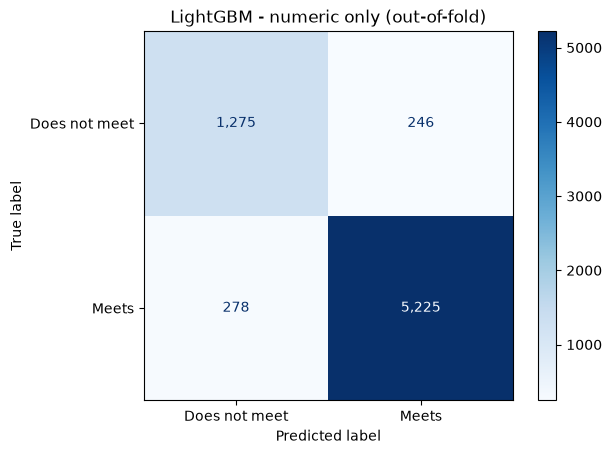

False positives (predicted meets, doesn't): 246
False negatives (predicted doesn't, meets): 278


,threshold,precision,recall,F1,false pos,false neg
0,0.3,0.941,0.967,0.954,332,182
1,0.4,0.948,0.958,0.953,292,229
2,0.5,0.955,0.949,0.952,246,278
3,0.6,0.959,0.937,0.948,218,346
4,0.7,0.963,0.921,0.942,193,433


In [11]:
final_model = make_gbm_pipeline(BEST_NAME, use_text=BEST_USE_TEXT, params=best_params[BEST_NAME])
oof_prob = cross_val_predict(final_model, X, y, cv=cv, groups=groups, method="predict_proba", n_jobs=5)[:, 1]
oof_pred = (oof_prob >= 0.5).astype(int)

cm = confusion_matrix(y, oof_pred)
ConfusionMatrixDisplay(cm, display_labels=["Does not meet", "Meets"]).plot(cmap="Blues", values_format=",")
plt.title(f"{BEST_LABEL} (out-of-fold)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"False positives (predicted meets, doesn't): {fp:,}")
print(f"False negatives (predicted doesn't, meets): {fn:,}")

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (oof_prob >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y, p), "recall": recall_score(y, p),
                 "F1": f1_score(y, p), "false pos": int(((p == 1) & (y == 0)).sum()),
                 "false neg": int(((p == 0) & (y == 1)).sum())})
pd.DataFrame(rows).round(3)

false pos- failing programs getting through

false neg- good programs missed

If funding a program that doesn’t pay off is the worse outcome, use a higher cutoff such as 0.6 or 0.7.

If overlooking good programs is the worse outcome, use a lower one such as 0.3 or 0.4.

If you have no strong preference, 0.5 is a reasonable default, and it’s what the rest of the notebook uses.

In [12]:
if RUN_NESTED:
    outer, inner = GroupKFold(n_splits=5), GroupKFold(n_splits=3)
    nested_auc = []
    for tr, te in outer.split(X, y, groups):
        rs = RandomizedSearchCV(make_gbm_pipeline(BEST_NAME, use_text=BEST_USE_TEXT), PARAM_DIST[BEST_NAME],
                                n_iter=N_ITER, cv=inner, scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE)
        rs.fit(X.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])
        nested_auc.append(roc_auc_score(y.iloc[te], rs.predict_proba(X.iloc[te])[:, 1]))
    print(f"Nested ROC-AUC: {np.mean(nested_auc):.3f} ± {np.std(nested_auc):.3f}   (tuned-on-same-folds: {raw[BEST_LABEL]['roc_auc']:.3f})")
else:
    print("Skipped (RUN_NESTED = False)")

Skipped (RUN_NESTED = False)


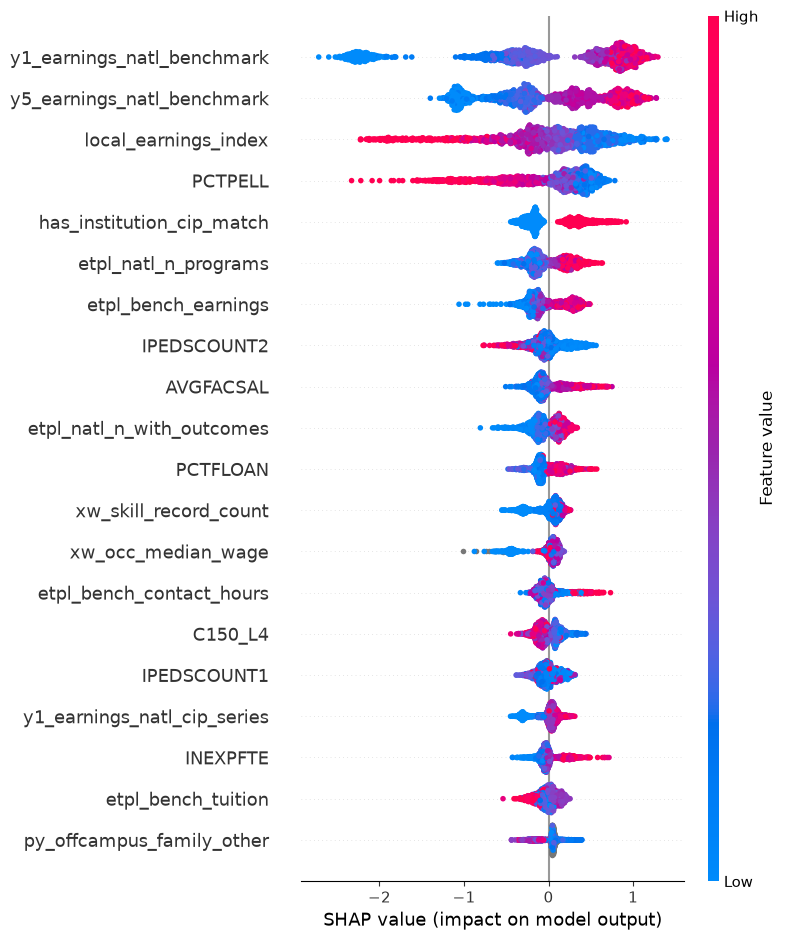

In [13]:
final_model.fit(X, y)
prep, clf = final_model.named_steps["prep"], final_model.named_steps["clf"]
feature_names = [n.replace("num__", "").replace("text__", "text: ") for n in prep.get_feature_names_out()]

try:
    import shap
    Xt = prep.transform(X)
    sample = np.random.RandomState(RANDOM_STATE).choice(len(Xt), size=min(2000, len(Xt)), replace=False)
    sv = shap.TreeExplainer(clf).shap_values(Xt[sample])
    if isinstance(sv, list):          # older shap + LightGBM returns one array per class
        sv = sv[1]
    shap.summary_plot(sv, Xt[sample], feature_names=feature_names, max_display=20)
except ImportError:
    print("shap not installed; showing built-in importances instead")
    imp = pd.Series(clf.feature_importances_, index=feature_names).sort_values(ascending=False).head(20)
    imp[::-1].plot.barh(figsize=(7, 6), title="Feature importance (split-based)")
    plt.tight_layout(); plt.show()

**Notes:**

The plot shows the top 20 features for the final LightGBM model (numeric only), using a random sample of 2,000 labeled programs. Each dot is one program. Dots to the right push that program's prediction toward "meets," and dots to the left push toward "does not meet." Color shows the feature's value (red = high, blue = low). Features are ranked by average impact.

**Main drivers:**
- **`y1_earnings_natl_benchmark` / `y5_earnings_natl_benchmark` (top two):** programs in fields that pay well nationally are pushed strongly toward "meets," and low-paying fields are pushed strongly toward "does not meet." These have the widest spread, so the model relies mostly on field-level earnings.
- **`etpl_bench_earnings`, `AVGFACSAL`, `PCTFLOAN`, `xw_occ_median_wage`:** higher values push toward "meets," which is plausible.

**Signals that come from how the label is built (not discoveries):**
- **`local_earnings_index` (3rd):** higher values push toward "does not meet." The label divides earnings by this index, so a higher index lowers adjusted earnings by design.

**Signals to read with caution:**
- **`PCTPELL` (4th):** a higher Pell share pushes toward "does not meet." This reflects students' circumstances as much as program quality, so it is a fairness concern (see Step 11).
- **`C150_L4` (completion rate):** higher values push slightly toward "does not meet," the opposite of what we would expect. This is likely a confounder (for example, short programs with high completion but low earnings). The plot shows what the model learned, not a causal effect.
- **`has_institution_cip_match` and `IPEDSCOUNT2`:** both have clear effects, but they may reflect data linkage or coverage more than program quality. Check the data dictionary before explaining them.

**Compared with the LR coefficients:** the top drivers and their directions match (field-level earnings up, local earnings index and Pell share down). The overlapping tuition and short-term-certificate features no longer show offsetting effects in the top 20, which was the main reason for using SHAP.

**Caveats:**
- SHAP describes how the model behaves, not what causes earnings.
- When features overlap (the ETPL benchmarks, the national earnings columns), SHAP splits credit between them, so no single bar should be read too literally.
- Because the label is built from earnings, field-level benchmarks ranking first is expected.

In [14]:
rows = []
for grp, idx in labeled.groupby("control").groups.items():
    pos = labeled.index.get_indexer(idx)
    yt, yp, pp = y.loc[idx], oof_pred[pos], oof_prob[pos]
    rows.append({"control": grp, "programs": len(idx), "actual pass rate": yt.mean(), "predicted pass rate": yp.mean(),
                 "precision": precision_score(yt, yp, zero_division=0), "recall": recall_score(yt, yp, zero_division=0),
                 "F1": f1_score(yt, yp, zero_division=0),
                 "ROC-AUC": roc_auc_score(yt, pp) if yt.nunique() > 1 else np.nan})
pd.DataFrame(rows).round(3)

,control,programs,actual pass rate,predicted pass rate,precision,recall,F1,ROC-AUC
0,Private for-profit,2737,0.566,0.535,0.925,0.875,0.899,0.954
1,Private non-profit,306,0.758,0.807,0.887,0.944,0.914,0.900
2,Public,3981,0.935,0.944,0.971,0.981,0.976,0.920


In [15]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

df["p_vae_gbm"] = final_model.predict_proba(df[["program_text"] + NUMERIC_FEATURES])[:, 1]
df.loc[labeled.index, "p_vae_oof"] = oof_prob

out = df[["UNITID", "INSTNM", "state", "CIPCODE", "CIPDESC", "control",
          "vae_positive_local", "earnings_1yr", "p_vae_gbm", "p_vae_oof"]]
out.to_csv(f"{OUTPUT_DIR}/lgbm_predictions.csv", index=False)
joblib.dump(final_model, f"{OUTPUT_DIR}/lgbm_model.joblib")
results_df.to_csv(f"{OUTPUT_DIR}/lgbm_cv_results.csv")
with open(f"{OUTPUT_DIR}/best_params.json", "w") as f:
    json.dump({"best_variant": BEST_LABEL, "params": best_params}, f, indent=2, default=str)

print("Saved predictions:", out.shape)
print("Saved model, CV results and best params to:", OUTPUT_DIR)

Saved predictions: (26678, 10)
Saved model, CV results and best params to: ../../../models/lgbm_xgboost


## Conclusion

**Final model:** LightGBM on the numeric features only (no TF-IDF text). It trains faster than XGBoost, and the two performed the same.

**Performance (5-fold CV, folds grouped by school):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Always guess "meets" (dummy) | 0.783 | 0.783 | 1.000 | 0.879 | 0.500 |
| LR text + numeric (baseline) | 0.886 | 0.961 | 0.891 | 0.925 | 0.947 |
| **LightGBM numeric only** | **0.925** | **0.955** | **0.950** | **0.952** | **0.960** |

- **Boosted trees beat the LR baseline** on every headline metric except precision, which is essentially unchanged (0.961 vs 0.955, within fold-to-fold variation). The tuned CV ROC-AUC was 0.9603 for both XGBoost and LightGBM.
- **The biggest gain is recall:** the LR missed about 11% of programs that meet the standard, and LightGBM misses about 5%.
- **Text did not help.** Numeric-only and text + numeric scored the same to within 0.001 on every metric for both libraries. The numeric features already include field-level earnings benchmarks, so the field name and job titles add nothing new. This matches the LR notebook, where text added only +0.004 ROC-AUC.
- **XGBoost and LightGBM were tied** (ROC-AUC 0.960 ± 0.004 for both). The "Best by CV ROC-AUC" line in Step 7 is a tiebreak within noise, so we chose on training speed.

**Errors (out-of-fold, threshold 0.5):** 6,500 of 7,024 programs correct (92.5%, vs 88.6% for the LR).
- **False positives: 246.** About 16% of failing programs slip through (LR: 199, 13%).
- **False negatives: 278,** down from 601 for the LR. Good programs overlooked fell by more than half.
- **A "does not meet" prediction is right 82% of the time** (1,275 of 1,553), up from 69% for the LR. It should still prompt review, not automatic rejection.
- **Threshold:** raising the cutoff from 0.5 to 0.7 cuts false positives from 246 to 193 but raises false negatives from 278 to 433 (precision 0.963, recall 0.921). Lowering it to 0.3 does the opposite (332 false positives, 182 false negatives). The right cutoff depends on which mistake matters more to stakeholders. We used 0.5 as the default.

**Top signals (SHAP):**
- **Toward "meets":** high national field earnings (`y1/y5_earnings_natl_benchmark`, the two strongest features), plus `etpl_bench_earnings`, `AVGFACSAL`, `PCTFLOAN` and `xw_occ_median_wage`.
- **Toward "does not meet":** higher `PCTPELL` (Pell share) and higher `local_earnings_index`.
- **Built into the label, not discoveries:** `local_earnings_index` is a strong negative because the label divides earnings by it.
- **Read with caution:** `C150_L4` (completion rate) pushes slightly toward "does not meet," likely a confounder. `has_institution_cip_match` and `IPEDSCOUNT2` may reflect data linkage more than program quality. SHAP shows what the model learned, not what causes earnings.
- **Agrees with the LR** on the main drivers (field earnings up, local earnings index and Pell share down).

**Fairness (by school type):** _[fill in from Step 11: recall for for-profit programs vs the LR's 0.755, and any gap between actual and predicted pass rates]_

**Honest score (nested CV):** _[fill in from Step 9 if run; expect it to land slightly below 0.960]_

**Limitations:**
- The label is an estimate of the official Workforce Pell earnings test: all-completer earnings instead of Pell-recipient earnings, and an ETPL earnings index instead of BEA price parities.
- Only 26% of programs (7,024 of 26,678) have a label, and for-profit schools are over-represented among them (39% of labeled vs 16% overall), so results may not carry over evenly to unlabeled programs.
- Hyperparameters were tuned and scored on the same folds, so scores are slightly optimistic. The numeric-only model reuses hyperparameters tuned on text + numeric.
- Class weighting (`scale_pos_weight`) pushes probabilities toward "does not meet," so the scores are better for ranking programs than as literal probabilities.
- `PCTPELL` stays a concern even though race and ethnicity shares were excluded, because it can act as a stand-in for who a school serves.

**Next steps:** run nested CV for the honest ROC-AUC, check calibration by school type before using scores in the Opportunity Score, extend the fairness check to HBCU / HSI / tribal / rural schools, and choose the final threshold with stakeholders.